In [1]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import st_gears


In [2]:
refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)

refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns


# Convert scaled values in queryAD.X to counts by reversing scaling (if possible).
# If you know the scaling parameters (mean, std, min, max, etc.), you can invert the transformation.
# If not, a common approach is to exponentiate if log1p was used, or rescale to integers.
# Here, we'll assume log1p was used (common in scRNA-seq), so we invert with expm1 and round to integers.

import numpy as np

# If queryAD.X is a sparse matrix, convert to dense for transformation
if hasattr(queryAD.X, "toarray"):
    X_dense = queryAD.X.toarray()
else:
    X_dense = queryAD.X

# Invert log1p transformation (if that was the scaling used)
X_counts = np.expm1(X_dense)
X_counts[X_counts < 0] = 0  # Ensure no negative counts

queryAD.X = X_counts



sc.pp.normalize_total(refAD, target_sum=1e2)
sc.pp.normalize_total(queryAD, target_sum=1e2)

sc.pp.log1p(refAD)
sc.pp.log1p(queryAD)

sc.pp.scale(refAD)
sc.pp.scale(queryAD)

/home/adyprat/anaconda3/envs/stgears/lib/python3.10/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/stgears/lib/python3.10/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/stgears/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:197: UserWarning: Some cells have zero counts
  warn(UserWarning('Some cells have zero counts'))


In [3]:
refAD.obsm['spatial'] = np.column_stack([refAD.obs[['New_X', 'New_Y']].values, np.ones(refAD.shape[0])])
queryAD.obsm['spatial'] = np.column_stack([queryAD.obs[['New_X', 'New_Y']].values, np.zeros(queryAD.shape[0])])


In [4]:
slicesl = [queryAD, refAD]

In [5]:
import os
import st_gears
import warnings

warnings.filterwarnings('ignore')

grp_col = 'CellType'  # name of column in adata.obs that stores grouping information, either cluster or annotation information
binning_on = False  # only turn granularity adjusting on, when you have over 3000 spots in any one of the sections.

# set uniform_weight to False and filter_by_label to True if you trust in your groupping result, and sections are not too far from each other. Otherwise set uniform_weight to True and filter_by_label to False.
uniform_weight = False  # False if using Distributive Constraints, else True
filter_by_label = True  # Filter groups of spot that do not co-occur in two sections when computing anchors

# binning
if binning_on:
    step = 2  # step size for binning. Check your xy coordinates first. For example, when adjacent spots roughly sits 10 away from each other, setting step to 20 would decrease spots for 4 times in binning result. Remain roughly at least 200 spots in each section after binning.
    slice_srk_li = [st_gears.binning(slice_, grp_col, step) for slice_ in slicesl]  # 'slice_srk_li' means 'shrinked slice list'
else:
    slice_srk_li = slicesl

# Compute anchors
anncell_cid = st_gears.helper.gen_anncell_cid_from_all(slice_srk_li, grp_col)
pili, tyscoreli, alphali, regis_ilist, ali, bli = st_gears.serial_align(slice_srk_li, anncell_cid, label_col=grp_col, start_i=0, end_i=len(slicesl)-1,  # index of start and end section from slicesl to be aligned
tune_alpha_li=[0.8, 0.2, 0.05, 0.013],  # regularization factor list, recommend to fill values exponentially change among 0 and 1. Longer list indicates finer tuning resolution
numItermax=200,  # max number of iteration during optimization
dissimilarity_val='kl', dissimilarity_weight_val='kl',
    uniform_weight=uniform_weight, map_method_dis2wei='logistic',
    filter_by_label=filter_by_label,
    use_gpu=True, verbose=True)  # show each iteration or not


# Rigid registration
fil_pc = 20  # not recommended to change # fil_pc_rigid / 100 * (maximum_probability - minimum_probability) + minimum_probability is set as theshhold to filter anchors
slice_srk_li = st_gears.stack_slices_pairwise_rigid([slice_srk_li[i] for i in regis_ilist], pili,label_col=grp_col,fil_pc=fil_pc,  filter_by_label=filter_by_label)


# elastic registration
if binning_on:
    pixel_size = step  # pixel step size of elastic field. 
else:
    pixel_size = 1  # if not binned, input rough distance between adjacent spots on each section. 
sigma = 1  # not recommended to change. kernel size of Gaussian Filters, with a higher value indicating a smoother elastic field
slice_srk_li = st_gears.stack_slices_pairwise_elas_field([slice_srk_li[i] for i in regis_ilist], pili,label_col=grp_col,pixel_size=pixel_size,fil_pc=fil_pc,filter_by_label=filter_by_label,sigma=sigma)

# interpolate reconstruction result, back to original resolution
if binning_on:
    slicesl = st_gears.interpolate(slice_srk_li, slicesl)
else:
    slicesl = slice_srk_li

0 0
It.  |Loss        |Relative loss|Absolute loss
------------------------------------------------
    0|8.205523e+05|0.000000e+00|0.000000e+00
    1|5.812792e+05|4.116320e-01|2.392731e+05
    2|3.263066e+04|1.681390e+01|5.486485e+05
    3|9.808245e+03|2.326860e+00|2.282241e+04
    4|8.236818e+03|1.907809e-01|1.571428e+03
    5|7.818027e+03|5.356737e-02|4.187911e+02
    6|7.683372e+03|1.752550e-02|1.346550e+02
    7|7.637155e+03|6.051514e-03|4.621635e+01
    8|7.622647e+03|1.903305e-03|1.450822e+01
    9|7.617404e+03|6.882831e-04|5.242930e+00
   10|7.615740e+03|2.184738e-04|1.663839e+00
   11|7.615327e+03|5.422039e-05|4.129060e-01
   12|7.615248e+03|1.047634e-05|7.977994e-02
   13|7.615227e+03|2.727296e-06|2.076898e-02
   14|7.615222e+03|6.119605e-07|4.660215e-03
   15|7.615220e+03|2.958172e-07|2.252713e-03
   16|7.615217e+03|3.565484e-07|2.715194e-03
   17|7.615210e+03|9.146922e-07|6.965573e-03
   18|7.615208e+03|2.746884e-07|2.091809e-03
   19|7.615208e+03|6.577409e-08|5.008834e-04


In [6]:
slicesl

[AnnData object with n_obs × n_vars = 4671 × 16
     obs: 'Image', 'Object ID', 'Object type', 'Name', 'Classification', 'Parent', 'ROI', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Nucleus: DAPI sum', 'Nucleus: DAPI std dev', 'Nucleus: DAPI max', 'Nucleus: DAPI min', 'Nucleus: DAPI range', 'Nucleus: CD8 sum', 'Nucleus: CD8 std dev', 'Nucleus: CD8 max', 'Nucleus: CD8 min', 'Nucleus: CD8 range', 'Nucleus: CD20 sum', 'Nucleus: CD20 std dev', 'Nucleus: CD20 max', 'Nucleus: CD20 min', 'Nucleus: CD20 range', 'Nucleus: CD4 sum', 'Nucleus: CD4 std dev', 'Nucleus: CD4 max', 'Nucleus: CD4 min', 'Nucleus: CD4 range', 'Nucleus: GZMB sum', 'Nucleus: GZMB std dev', 'Nucleus: GZMB max', 'Nucleus: GZMB min', 'Nucleus: GZMB range', 'Nucleus: FOXP3 sum', 'Nucleus: FOXP3 std dev', 'Nucleus: FOXP3 max', 'Nucleus: FOXP3 min', 'Nucleus: FOXP3 range', 'Nucleus: Ki67 sum', 'Nucleus: 

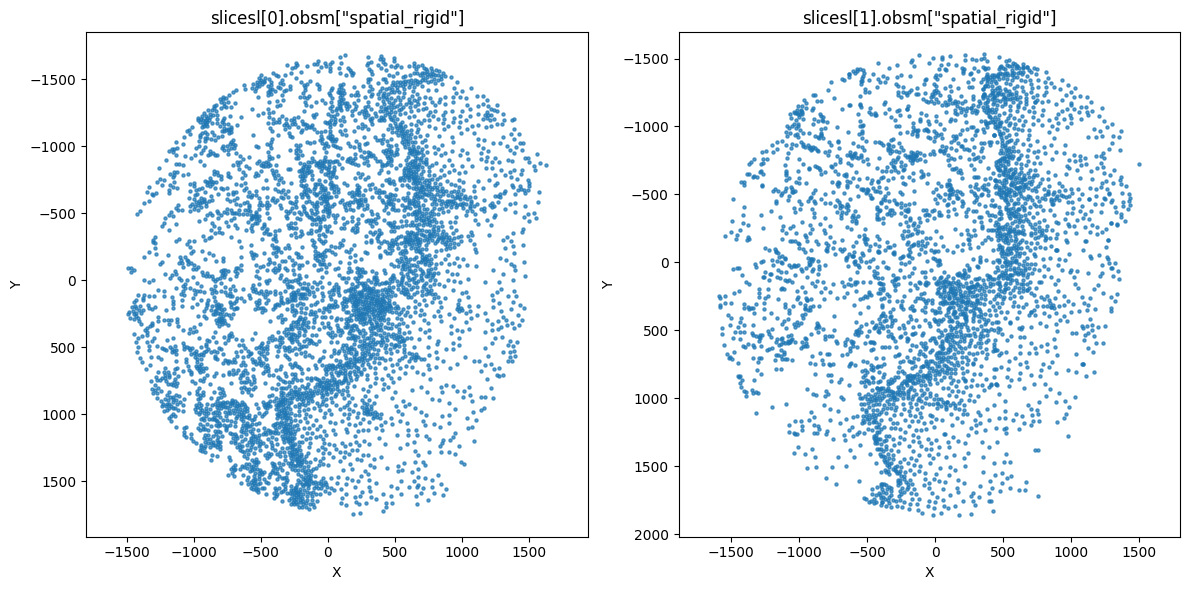

Number of matches (elastic): 2595 / 4671
Match percentage (elastic): 55.56%


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes):
    spatial_elas = slicesl[i].obsm['spatial_rigid']
    ax.scatter(spatial_elas[:, 0], spatial_elas[:, 1], s=5, alpha=0.7)
    ax.set_title(f'slicesl[{i}].obsm["spatial_rigid"]')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axis('equal')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()






# For each query cell, find the nearest ref cell in the reconstructed (elastic) space using 'spatial_elas' coordinates
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the elastic registration coordinates
ref_coords_elas = refAD.obsm['spatial_rigid'][:, :2]
query_coords_elas = queryAD.obsm['spatial_rigid'][:, :2]

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree_elas = cKDTree(ref_coords_elas)
dists_elas, idxs_elas = tree_elas.query(query_coords_elas, k=1)

# Compare cell types
matches_elas = query_celltypes == ref_celltypes[idxs_elas]

# Optionally, print or summarize the results
print(f"Number of matches (elastic): {matches_elas.sum()} / {len(matches_elas)}")
print(f"Match percentage (elastic): {matches_elas.mean()*100:.2f}%")

# Store nearest ref cell type and match result in queryAD.obs
queryAD.obs['NearestRefCellType_elas'] = ref_celltypes[idxs_elas]
queryAD.obs['CellTypeMatch_elas'] = matches_elas




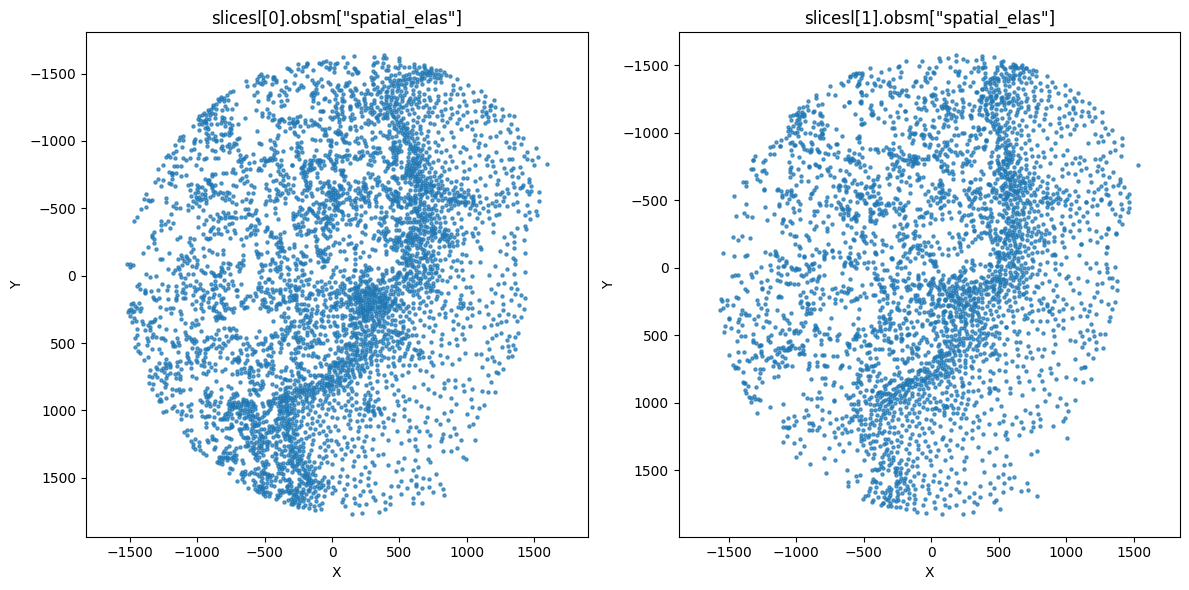

Number of matches (elastic): 2548 / 4671
Match percentage (elastic): 54.55%


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes):
    spatial_elas = slicesl[i].obsm['spatial_elas']
    ax.scatter(spatial_elas[:, 0], spatial_elas[:, 1], s=5, alpha=0.7)
    ax.set_title(f'slicesl[{i}].obsm["spatial_elas"]')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.axis('equal')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()




# For each query cell, find the nearest ref cell in the reconstructed (elastic) space using 'spatial_elas' coordinates
from scipy.spatial import cKDTree

# Get coordinates from refAD and queryAD using the elastic registration coordinates
ref_coords_elas = refAD.obsm['spatial_elas'][:, :2]
query_coords_elas = queryAD.obsm['spatial_elas'][:, :2]

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
tree_elas = cKDTree(ref_coords_elas)
dists_elas, idxs_elas = tree_elas.query(query_coords_elas, k=1)

# Compare cell types
matches_elas = query_celltypes == ref_celltypes[idxs_elas]

# Optionally, print or summarize the results
print(f"Number of matches (elastic): {matches_elas.sum()} / {len(matches_elas)}")
print(f"Match percentage (elastic): {matches_elas.mean()*100:.2f}%")

# Store nearest ref cell type and match result in queryAD.obs
queryAD.obs['NearestRefCellType_elas'] = ref_celltypes[idxs_elas]
queryAD.obs['CellTypeMatch_elas'] = matches_elas




In [11]:
queryAD.obsm['X_STGEARS_spatial'] = queryAD.obsm['spatial_elas'][:,:2].copy()

In [12]:
queryAD.write_h5ad('query_STGEARS_Prot_tongue.h5ad')

In [13]:
refAD.obsm['X_STGEARS_spatial'] = refAD.obsm['spatial_elas'][:,:2].copy()
refAD.write_h5ad('ref_STGEARS_RNA_tongue.h5ad')

In [14]:
queryAD.obsm['spatial_elas'][:,:2]

array([[  165.11284479, -1633.52418599],
       [  384.6327523 , -1636.33905439],
       [   80.93582759, -1626.01962477],
       ...,
       [  598.57284476,  1646.75741081],
       [  669.65449465,  1689.13045181],
       [  601.08982204,  1688.06248771]])

In [22]:
refAD.obsm['spatial_elas']

array([[-257.90049778, -477.90868297,    1.        ],
       [-226.93045547, -477.87506423,    1.        ],
       [-210.1529812 , -477.80877366,    1.        ],
       ...,
       [  91.06312806,  512.38934259,    1.        ],
       [ 110.27476114,  509.90530061,    1.        ],
       [ 125.31431915,  512.40216502,    1.        ]])

In [15]:
queryAD.obsm['X_STGEARS_spatial']

array([[ 229.47903813, -466.14793937,    0.        ],
       [ 263.63135795, -461.17834073,    0.        ],
       [ 283.62238608, -463.73889991,    0.        ],
       ...,
       [  88.20011034,  511.20981614,    0.        ],
       [ 100.79834118,  511.3727785 ,    0.        ],
       [ 122.95401364,  511.03646835,    0.        ]])

In [13]:
queryAD.write_h5ad('query_STGEARS.h5ad')